# Multimodal Sentiment Analysis with CLIP

This notebook predicts the sentiment (negative / neutral / positive) of
tweets that contain both an image and a text, using frozen
**CLIP ViT-L/14** embeddings.

Plan:
1. Load the MVSA-Multiple posts and their cached CLIP embeddings.
2. Build baselines: majority class, zero-shot CLIP, logistic regression.
3. Train a custom fusion head on top of the frozen embeddings.
4. Compare all models on the same test set.

The data preparation and embedding extraction are in `clip_utils.py`; see
`clip.API.ipynb` for an introduction to the CLIP API.

References:
- Niu et al., *Sentiment Analysis on Multi-view Social Data*, MMM 2016
  (MVSA dataset)
- Xu and Mao, *MultiSentiNet*, CIKM 2017 (label aggregation)
- Radford et al., *Learning Transferable Visual Models From Natural Language
  Supervision*, 2021 (CLIP)

## Imports

In [1]:
%load_ext autoreload
%autoreload 2

# System libraries.
import logging
import os

# Third-party libraries.
import pandas as pd
import torch

# Use all CPU cores for the CLIP text encoder.
torch.set_num_threads(os.cpu_count())

In [2]:
import helpers.hdbg as hdbg
import helpers.hnotebook as hnotebook

import clip_utils as cliputil

_LOG = logging.getLogger(__name__)

# Initialize notebook configuration and logging.
hdbg.init_logger(verbosity=logging.INFO)
hnotebook.config_notebook()
cliputil.init_loggers(_LOG)

INFO  > /usr/local/lib/python3.12/site-packages/ipykernel_launcher.py -f /root/.local/share/jupyter/runtime/kernel-78897fcf-dcf5-4200-aacf-0a4aa98e2da3.json


## Load the Data

The first run of the cells below builds the post table and extracts the
CLIP embeddings (about 3 hours on CPU). Later runs load both from
`data/processed/` in a few seconds.

In [3]:
LABELS_PATH = "data/processed/labels.csv"
CACHE_PATH = "data/processed/clip_embeddings.npz"

# Build the post table and the embedding cache only if they are missing.
if not os.path.exists(LABELS_PATH):
    cliputil.build_mvsa_table("data/raw/MVSA", LABELS_PATH)
if not os.path.exists(CACHE_PATH):
    cliputil.extract_embeddings(pd.read_csv(LABELS_PATH), CACHE_PATH)
df, emb = cliputil.load_project_data(LABELS_PATH, CACHE_PATH)
print(f"Posts: {len(df)}  Image embeddings: {emb['image'].shape}  "
      f"Text embeddings: {emb['text'].shape}")

Posts: 17025  Image embeddings: (17025, 768)  Text embeddings: (17025, 768)


The classes are imbalanced, and the stratified split keeps the same
proportions in train, validation, and test.

In [4]:
cliputil.summarize_splits(df)

label,negative,neutral,positive,total
split,,,,
train,1039,3526,9054,13619
val,130,441,1132,1703
test,130,441,1132,1703


## Evaluation Protocol

- **Main metric: macro F1**, the average F1 over the 3 classes. With about
  2/3 positive posts, a model that always says "positive" already gets high
  accuracy, while its macro F1 stays low.
- Hyperparameters are chosen on the **validation** split. The **test**
  split is used only to report the final numbers.
- **Same training budget for every trained model**: the linear baselines
  and the 3 fusion heads all use the same loop (class-weighted
  cross-entropy, AdamW, batch 128, learning rate 1e-3, weight decay 1e-2)
  for exactly `EPOCHS` epochs. The weights of the epoch with the best
  validation macro F1 are kept.

In [5]:
EPOCHS = 20
TRAIN = dict(epochs=EPOCHS, batch_size=128, lr=1e-3, weight_decay=1e-2)

y = df["label_id"].to_numpy()
train_idx = cliputil.split_indices(df, "train")
val_idx = cliputil.split_indices(df, "val")
test_idx = cliputil.split_indices(df, "test")

results = {}
test_preds = {}
histories = {}


def add_result(name, model, make_batch):
    """
    Evaluate a trained model on the test split and store the results.
    """
    probs, gates = cliputil.predict_head(model, make_batch, test_idx)
    y_pred = probs.argmax(axis=1)
    results[name] = cliputil.evaluate(y[test_idx], y_pred)
    test_preds[name] = (y[test_idx], y_pred)
    return gates

## Baseline 0: Majority Class

Always predict the most frequent training label. Every model must beat
this.

In [6]:
_, y_train = cliputil.split_xy(df, emb["image"], "train")
_, y_test = cliputil.split_xy(df, emb["image"], "test")

y_pred = cliputil.majority_baseline(y_train, len(y_test))
results["Majority class"] = cliputil.evaluate(y_test, y_pred)
test_preds["Majority class"] = (y_test, y_pred)
cliputil.results_table(results)

,accuracy,macro_f1,precision_negative,recall_negative,precision_neutral,recall_neutral,precision_positive,recall_positive
Majority class,0.665,0.266,0.0,0.0,0.0,0.0,0.665,1.0


## Baseline 1: Zero-Shot CLIP

No training: compare each image and each text with one prompt per class,
as in `clip.API.ipynb`, and average the two probability vectors. Only the
prompts need the CLIP text encoder.

In [7]:
model, processor = cliputil.load_clip()

image_prompts = [
    "a photo with a negative mood",
    "a photo with a neutral mood",
    "a photo with a positive mood",
]
text_prompts = [
    "a negative message",
    "a neutral message",
    "a positive message",
]

probs_img = cliputil.zero_shot_probs(
    emb["image"][test_idx], image_prompts, model, processor
)
probs_txt = cliputil.zero_shot_probs(
    emb["text"][test_idx], text_prompts, model, processor
)
y_pred = ((probs_img + probs_txt) / 2).argmax(axis=1)
name = "Zero-shot (image+text)"
results[name] = cliputil.evaluate(y[test_idx], y_pred)
test_preds[name] = (y[test_idx], y_pred)
cliputil.results_table(results)

WARNING Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.


Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

Loaded openai/clip-vit-large-patch14 on cpu


,accuracy,macro_f1,precision_negative,recall_negative,precision_neutral,recall_neutral,precision_positive,recall_positive
Zero-shot (image+text),0.579,0.401,0.217,0.238,0.273,0.218,0.711,0.759
Majority class,0.665,0.266,0.000,0.000,0.000,0.000,0.665,1.000


## Baseline 2: Logistic Regression on Frozen Embeddings

A linear classifier (logistic regression) on 3 inputs:
- `image`: image embedding only
- `text`: text embedding only
- `concat`: both embeddings side by side

The features are standardized with the training mean and std. It is
trained with the same loop and number of epochs as the fusion heads.

In [8]:
for kind in cliputil.FEATURE_SETS:
    X = cliputil.build_features(emb, kind)
    name = f"LogReg ({kind})"
    clf = cliputil.make_linear_head(X, train_idx)
    clf, histories[name] = cliputil.train_head(
        clf, cliputil.feature_batch(X), y, train_idx, val_idx, **TRAIN
    )
    add_result(name, clf, cliputil.feature_batch(X))

epoch 1  train loss 0.9802  val macro F1 0.4283
epoch 2  train loss 0.8768  val macro F1 0.4409
epoch 3  train loss 0.8488  val macro F1 0.4617
epoch 4  train loss 0.8335  val macro F1 0.4769
epoch 5  train loss 0.8236  val macro F1 0.4662
epoch 6  train loss 0.8172  val macro F1 0.4704
epoch 7  train loss 0.8129  val macro F1 0.4881
epoch 8  train loss 0.8077  val macro F1 0.4758
epoch 9  train loss 0.8071  val macro F1 0.4761
epoch 10  train loss 0.8044  val macro F1 0.4829
epoch 11  train loss 0.8013  val macro F1 0.4808
epoch 12  train loss 0.8001  val macro F1 0.4795
epoch 13  train loss 0.7992  val macro F1 0.4865
epoch 14  train loss 0.8002  val macro F1 0.4687
epoch 15  train loss 0.7990  val macro F1 0.4770
epoch 16  train loss 0.7971  val macro F1 0.4776
epoch 17  train loss 0.7976  val macro F1 0.4802
epoch 18  train loss 0.7949  val macro F1 0.4826
epoch 19  train loss 0.7966  val macro F1 0.4761
epoch 20  train loss 0.7948  val macro F1 0.4814
Best val macro F1 0.4881 at e

## Baseline Results

In [9]:
cliputil.results_table(results)

,accuracy,macro_f1,precision_negative,recall_negative,precision_neutral,recall_neutral,precision_positive,recall_positive
LogReg (concat),0.581,0.504,0.272,0.623,0.385,0.490,0.821,0.612
LogReg (text),0.581,0.502,0.269,0.654,0.382,0.463,0.821,0.618
LogReg (image),0.566,0.489,0.255,0.677,0.371,0.444,0.819,0.601
Zero-shot (image+text),0.579,0.401,0.217,0.238,0.273,0.218,0.711,0.759
Majority class,0.665,0.266,0.000,0.000,0.000,0.000,0.665,1.000


Each row of a confusion matrix sums to 1, so the diagonal is the recall of
each class.

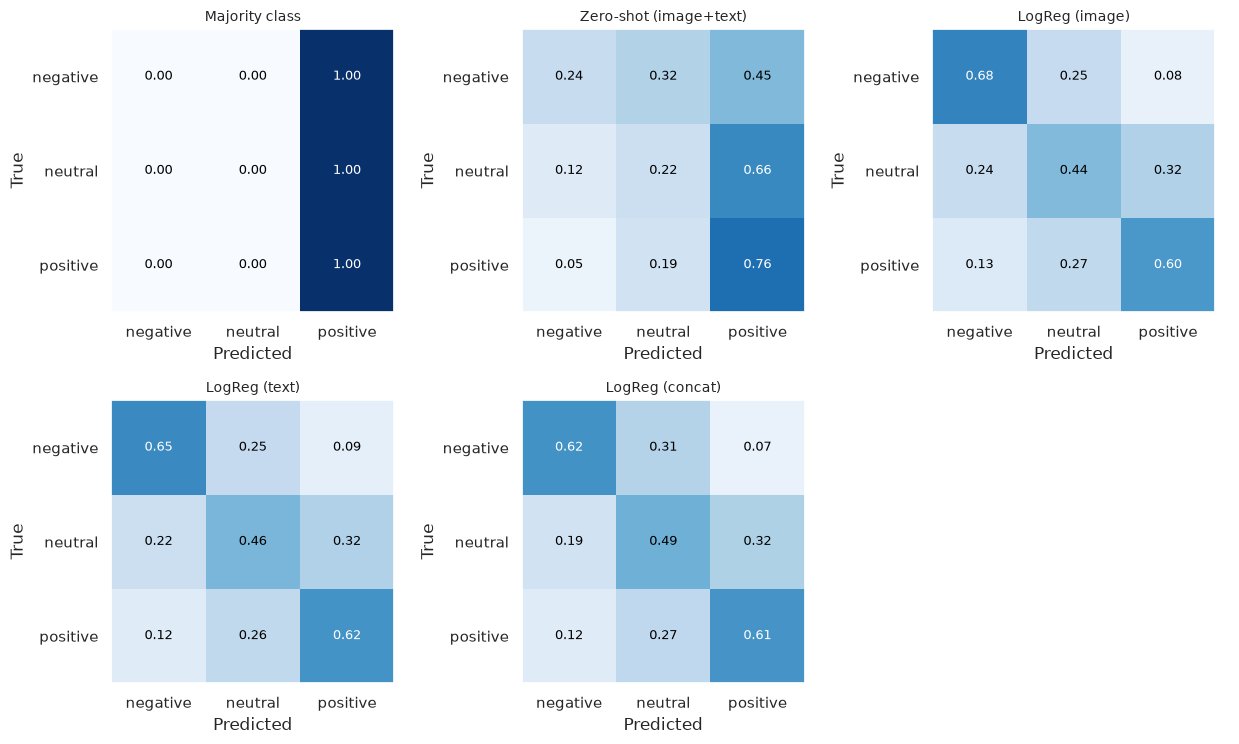

In [10]:
cliputil.plot_confusion_matrices(test_preds)

## Custom Fusion Heads

We train 3 small heads on top of the frozen CLIP features, with the same
training settings (`TRAIN`) as the linear baselines.

| Head | Input | Idea |
|---|---|---|
| H1 Stack | 768-d embeddings | standardize, average image and text, linear layer |
| H2 Gated fusion | 768-d embeddings | text is the anchor; the image is added through a learned gate |
| H3 Cross-attention | token features | image and text tokens attend to each other |

### H1: Stack Head

Each modality is standardized with the training mean and std, the two are
averaged with fixed weights 1/2, and one linear layer predicts the class.
This tests whether summing in CLIP's shared space works as well as
concatenation.

In [11]:
emb_batch = cliputil.embedding_batch(emb)

h1 = cliputil.make_stack_head(emb, train_idx)
print("H1 parameters:", cliputil.count_params(h1))
h1, histories["H1 Stack"] = cliputil.train_head(
    h1, emb_batch, y, train_idx, val_idx, **TRAIN
)
add_result("H1 Stack", h1, emb_batch)
cliputil.results_table(results)

H1 parameters: 2307
epoch 1  train loss 0.9617  val macro F1 0.4471
epoch 2  train loss 0.8397  val macro F1 0.4745
epoch 3  train loss 0.8071  val macro F1 0.4825
epoch 4  train loss 0.7870  val macro F1 0.4945
epoch 5  train loss 0.7740  val macro F1 0.4918
epoch 6  train loss 0.7657  val macro F1 0.4923
epoch 7  train loss 0.7605  val macro F1 0.5041
epoch 8  train loss 0.7548  val macro F1 0.5010
epoch 9  train loss 0.7542  val macro F1 0.4977
epoch 10  train loss 0.7482  val macro F1 0.5124
epoch 11  train loss 0.7454  val macro F1 0.5056
epoch 12  train loss 0.7438  val macro F1 0.5102
epoch 13  train loss 0.7432  val macro F1 0.5074
epoch 14  train loss 0.7431  val macro F1 0.4982
epoch 15  train loss 0.7398  val macro F1 0.4913
epoch 16  train loss 0.7393  val macro F1 0.5074
epoch 17  train loss 0.7390  val macro F1 0.5075
epoch 18  train loss 0.7365  val macro F1 0.5038
epoch 19  train loss 0.7364  val macro F1 0.5108
epoch 20  train loss 0.7353  val macro F1 0.5100
Best val 

,accuracy,macro_f1,precision_negative,recall_negative,precision_neutral,recall_neutral,precision_positive,recall_positive
H1 Stack,0.596,0.517,0.288,0.708,0.396,0.456,0.824,0.638
LogReg (concat),0.581,0.504,0.272,0.623,0.385,0.490,0.821,0.612
LogReg (text),0.581,0.502,0.269,0.654,0.382,0.463,0.821,0.618
LogReg (image),0.566,0.489,0.255,0.677,0.371,0.444,0.819,0.601
Zero-shot (image+text),0.579,0.401,0.217,0.238,0.273,0.218,0.711,0.759
Majority class,0.665,0.266,0.000,0.000,0.000,0.000,0.665,1.000


### H2: Gated Fusion (anchor = text)

The text is the main input. The image is added as `z + g * a`, where the
gate `g` (one number per post, between 0.05 and 0.95) is computed from both
modalities and their CLIP cosine similarity. The gate starts at 0.5.

In [12]:
h2 = cliputil.GatedFusionHead(anchor="text")
print("H2 parameters:", cliputil.count_params(h2))
h2, histories["H2 Gated"] = cliputil.train_head(
    h2, emb_batch, y, train_idx, val_idx, **TRAIN
)
h2_gates = add_result("H2 Gated", h2, emb_batch)
cliputil.results_table(results)

H2 parameters: 693509
epoch 1  train loss 0.8882  val macro F1 0.5174
epoch 2  train loss 0.7693  val macro F1 0.5179
epoch 3  train loss 0.7087  val macro F1 0.5079
epoch 4  train loss 0.6441  val macro F1 0.5349
epoch 5  train loss 0.5781  val macro F1 0.5207
epoch 6  train loss 0.5227  val macro F1 0.5009
epoch 7  train loss 0.4736  val macro F1 0.5120
epoch 8  train loss 0.4162  val macro F1 0.5094
epoch 9  train loss 0.3710  val macro F1 0.4999
epoch 10  train loss 0.3270  val macro F1 0.5116
epoch 11  train loss 0.2902  val macro F1 0.5155
epoch 12  train loss 0.2589  val macro F1 0.4940
epoch 13  train loss 0.2402  val macro F1 0.5117
epoch 14  train loss 0.2214  val macro F1 0.4942
epoch 15  train loss 0.1935  val macro F1 0.4907
epoch 16  train loss 0.1862  val macro F1 0.5097
epoch 17  train loss 0.1644  val macro F1 0.5076
epoch 18  train loss 0.1533  val macro F1 0.5121
epoch 19  train loss 0.1530  val macro F1 0.4966
epoch 20  train loss 0.1429  val macro F1 0.5075
Best va

,accuracy,macro_f1,precision_negative,recall_negative,precision_neutral,recall_neutral,precision_positive,recall_positive
H2 Gated,0.639,0.541,0.327,0.662,0.426,0.415,0.812,0.724
H1 Stack,0.596,0.517,0.288,0.708,0.396,0.456,0.824,0.638
LogReg (concat),0.581,0.504,0.272,0.623,0.385,0.490,0.821,0.612
LogReg (text),0.581,0.502,0.269,0.654,0.382,0.463,0.821,0.618
LogReg (image),0.566,0.489,0.255,0.677,0.371,0.444,0.819,0.601
Zero-shot (image+text),0.579,0.401,0.217,0.238,0.273,0.218,0.711,0.759
Majority class,0.665,0.266,0.000,0.000,0.000,0.000,0.665,1.000


The gate shows how much each post relies on the image. A higher mean `g`
for a class means the head uses the image more for that class.

In [13]:
cliputil.gate_table(h2_gates, y[test_idx])

,mean,std,min,max
label,,,,
negative,0.822,0.152,0.234,0.944
neutral,0.846,0.126,0.204,0.947
positive,0.769,0.198,0.098,0.948


### H3: Token-Level Cross-Modal Attention

H3 needs the token features (CLS + 8x8 image patches, and all text tokens),
extracted once with `python extract_tokens.py text` and
`python extract_tokens.py image`. They are read from disk batch by batch.

In [14]:
TOKENS_DIR = "data/processed/clip_tokens"
tok = cliputil.load_token_features(TOKENS_DIR)
assert (tok["ids"] == df["id"].to_numpy()).all(), "Token features do not match df"
tok_batch = cliputil.token_batch(tok)

h3 = cliputil.TokenCrossAttentionHead()
print("H3 parameters:", cliputil.count_params(h3))
h3, histories["H3 Cross-attn"] = cliputil.train_head(
    h3, tok_batch, y, train_idx, val_idx, **TRAIN
)
add_result("H3 Cross-attn", h3, tok_batch)
cliputil.results_table(results)

H3 parameters: 1518085
epoch 1  train loss 0.9674  val macro F1 0.5848
epoch 2  train loss 0.7874  val macro F1 0.5608
epoch 3  train loss 0.7334  val macro F1 0.5528
epoch 4  train loss 0.6728  val macro F1 0.5398
epoch 5  train loss 0.6271  val macro F1 0.5047
epoch 6  train loss 0.5563  val macro F1 0.5125
epoch 7  train loss 0.5257  val macro F1 0.5111
epoch 8  train loss 0.4836  val macro F1 0.5214
epoch 9  train loss 0.4336  val macro F1 0.5113
epoch 10  train loss 0.4175  val macro F1 0.5311
epoch 11  train loss 0.3798  val macro F1 0.5281
epoch 12  train loss 0.3385  val macro F1 0.4983
epoch 13  train loss 0.3231  val macro F1 0.5078
epoch 14  train loss 0.2867  val macro F1 0.5106
epoch 15  train loss 0.2519  val macro F1 0.4987
epoch 16  train loss 0.2257  val macro F1 0.5126
epoch 17  train loss 0.2183  val macro F1 0.5253
epoch 18  train loss 0.2094  val macro F1 0.5191
epoch 19  train loss 0.2005  val macro F1 0.4842
epoch 20  train loss 0.1705  val macro F1 0.5128
Best v

,accuracy,macro_f1,precision_negative,recall_negative,precision_neutral,recall_neutral,precision_positive,recall_positive
H3 Cross-attn,0.695,0.560,0.523,0.438,0.480,0.331,0.760,0.867
H2 Gated,0.639,0.541,0.327,0.662,0.426,0.415,0.812,0.724
H1 Stack,0.596,0.517,0.288,0.708,0.396,0.456,0.824,0.638
LogReg (concat),0.581,0.504,0.272,0.623,0.385,0.490,0.821,0.612
LogReg (text),0.581,0.502,0.269,0.654,0.382,0.463,0.821,0.618
LogReg (image),0.566,0.489,0.255,0.677,0.371,0.444,0.819,0.601
Zero-shot (image+text),0.579,0.401,0.217,0.238,0.273,0.218,0.711,0.759
Majority class,0.665,0.266,0.000,0.000,0.000,0.000,0.665,1.000


## Results

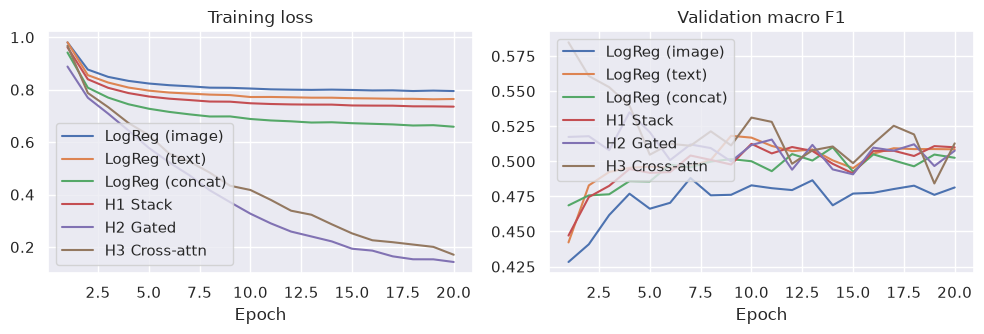

In [15]:
cliputil.plot_history(histories)

In [16]:
cliputil.results_table(results)

,accuracy,macro_f1,precision_negative,recall_negative,precision_neutral,recall_neutral,precision_positive,recall_positive
H3 Cross-attn,0.695,0.560,0.523,0.438,0.480,0.331,0.760,0.867
H2 Gated,0.639,0.541,0.327,0.662,0.426,0.415,0.812,0.724
H1 Stack,0.596,0.517,0.288,0.708,0.396,0.456,0.824,0.638
LogReg (concat),0.581,0.504,0.272,0.623,0.385,0.490,0.821,0.612
LogReg (text),0.581,0.502,0.269,0.654,0.382,0.463,0.821,0.618
LogReg (image),0.566,0.489,0.255,0.677,0.371,0.444,0.819,0.601
Zero-shot (image+text),0.579,0.401,0.217,0.238,0.273,0.218,0.711,0.759
Majority class,0.665,0.266,0.000,0.000,0.000,0.000,0.665,1.000


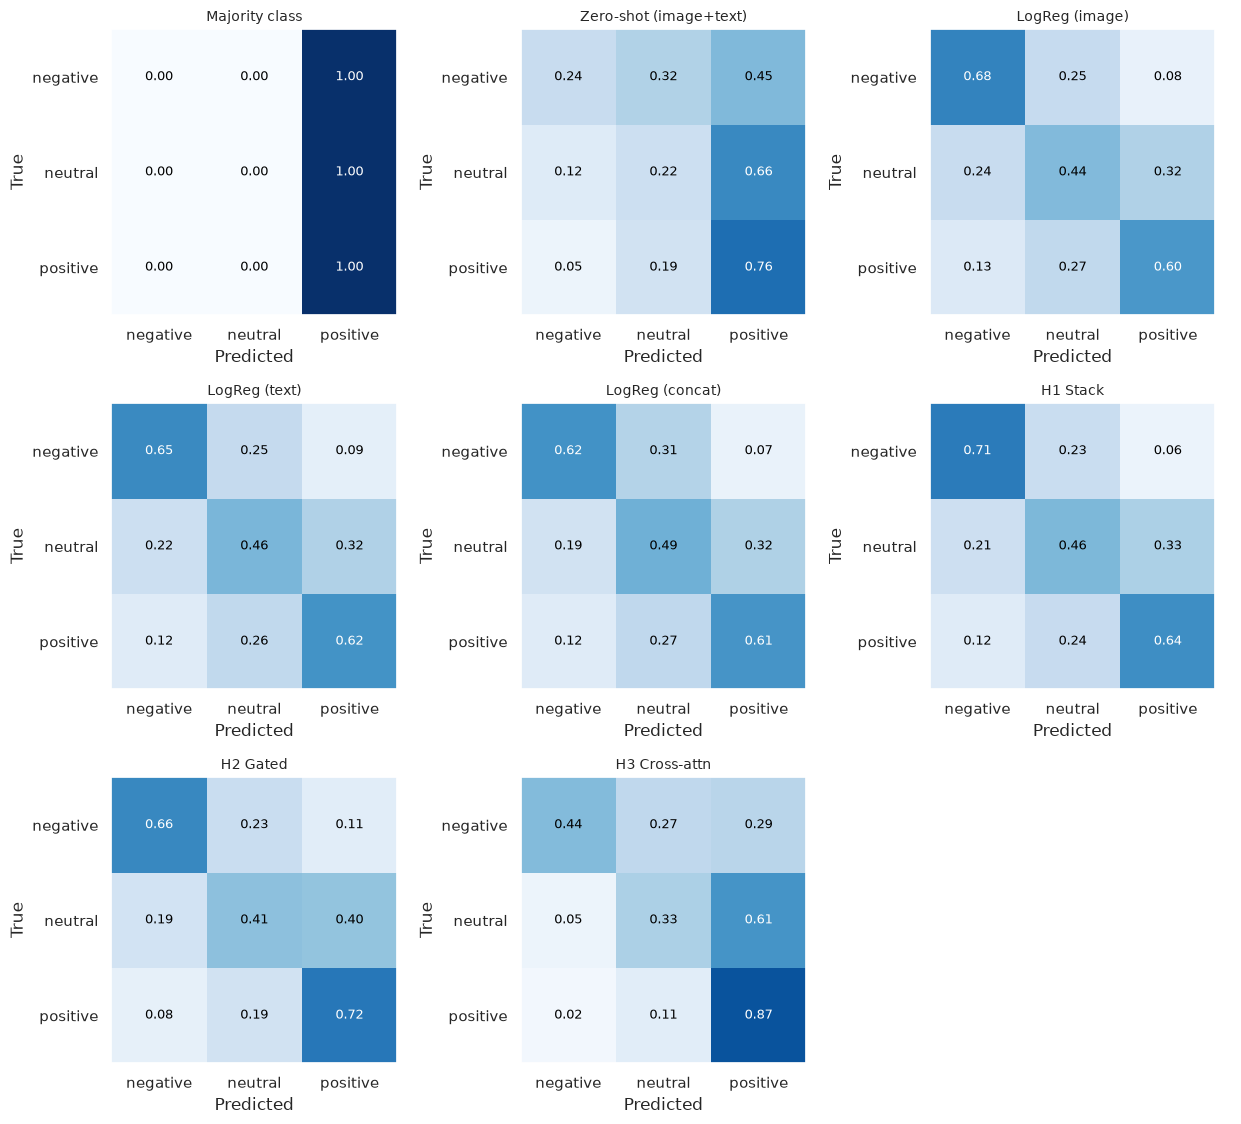

In [17]:
cliputil.plot_confusion_matrices(test_preds)

## Summary

TODO: summarize the comparison once the results are in.